In [13]:
%pip install certifi

Note: you may need to restart the kernel to use updated packages.


In [14]:
import certifi

print("Certifi installed successfully!")
print("Certificate location:", certifi.where())

Certifi installed successfully!
Certificate location: c:\Users\fairu\Desktop\ml-testing\movie-recommendation-system\.venv\Lib\site-packages\certifi\cacert.pem


In [15]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [16]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("All libraries imported successfully!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
Pandas: 3.1.1
NumPy: 2.5.5
Scikit-learn: 1.9.1


In [18]:
import os
import ssl
import certifi
import urllib.request
import zipfile
import time
import shutil

dataset_url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

dataset_folder = "../dataset"
zip_path = "../dataset/ml-100k.zip"

os.makedirs(dataset_folder, exist_ok=True)

# Use Certifi's trusted CA certificates
ssl_context = ssl.create_default_context(
    cafile=certifi.where()
)

print("Starting MovieLens dataset download...")

start_time = time.time()

# Download with SSL certificate verification
with urllib.request.urlopen(
    dataset_url,
    context=ssl_context
) as response:

    with open(zip_path, "wb") as file:
        shutil.copyfileobj(response, file)

print("Download completed!")
print("Download time:", round(time.time() - start_time, 2), "seconds")

# Extract dataset
print("\nExtracting dataset...")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(dataset_folder)

print("Extraction completed!")

print("\nDataset location:", os.path.abspath(dataset_folder))

Starting MovieLens dataset download...
Download completed!
Download time: 3.17 seconds

Extracting dataset...
Extraction completed!

Dataset location: c:\Users\fairu\Desktop\ml-testing\movie-recommendation-system\dataset


In [19]:
ratings_path = "../dataset/ml-100k/u.data"

ratings = pd.read_csv(
    ratings_path,
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

print("Ratings dataset loaded!")
print("Dataset shape:", ratings.shape)

display(ratings.head())

Ratings dataset loaded!
Dataset shape: (100000, 4)


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [20]:
movies_path = "../dataset/ml-100k/u.item"

movie_columns = [
    "movie_id", "title", "release_date",
    "video_release_date", "imdb_url", "unknown",
    "Action", "Adventure", "Animation", "Children",
    "Comedy", "Crime", "Documentary", "Drama",
    "Fantasy", "Film-Noir", "Horror", "Musical",
    "Mystery", "Romance", "Sci-Fi", "Thriller",
    "War", "Western"
]

movies = pd.read_csv(
    movies_path,
    sep="|",
    encoding="latin-1",
    names=movie_columns
)

print("Movies dataset loaded!")
print("Dataset shape:", movies.shape)

display(movies[["movie_id", "title", "release_date"]].head(10))

Movies dataset loaded!
Dataset shape: (1682, 24)


,movie_id,title,release_date
0,1,Toy Story (1995),01-Jan-1995
1,2,GoldenEye (1995),01-Jan-1995
2,3,Four Rooms (1995),01-Jan-1995
3,4,Get Shorty (1995),01-Jan-1995
4,5,Copycat (1995),01-Jan-1995
5,6,Shanghai Triad (Yao a yao yao dao waipo qiao) ...,01-Jan-1995
6,7,Twelve Monkeys (1995),01-Jan-1995
7,8,Babe (1995),01-Jan-1995
8,9,Dead Man Walking (1995),01-Jan-1995
9,10,Richard III (1995),22-Jan-1996


In [21]:
print("RATINGS DATASET")
print("---------------------------")
print("Total ratings:", len(ratings))
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies rated:", ratings["movie_id"].nunique())

print("\nMOVIES DATASET")
print("---------------------------")
print("Total movies:", len(movies))

RATINGS DATASET
---------------------------
Total ratings: 100000
Unique users: 943
Unique movies rated: 1682

MOVIES DATASET
---------------------------
Total movies: 1682


In [22]:
print("RATING STATISTICS")
print("---------------------------")

print(ratings["rating"].describe())

print("\nAverage rating:", round(ratings["rating"].mean(), 2))
print("Highest rating:", ratings["rating"].max())
print("Lowest rating:", ratings["rating"].min())

RATING STATISTICS
---------------------------
count    100000.000000
mean          3.529860
std           1.125674
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Average rating: 3.53
Highest rating: 5
Lowest rating: 1


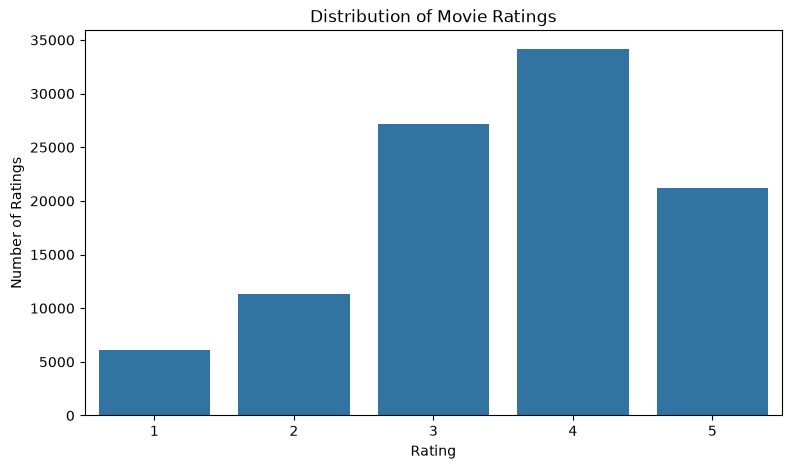

In [23]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=ratings,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

In [24]:
movie_rating_counts = ratings.groupby(
    "movie_id"
).size().reset_index(name="total_ratings")

movie_rating_counts = movie_rating_counts.merge(
    movies[["movie_id", "title"]],
    on="movie_id"
)

most_rated_movies = movie_rating_counts.sort_values(
    by="total_ratings",
    ascending=False
)

print("TOP 10 MOST RATED MOVIES")
print("---------------------------")

display(most_rated_movies.head(10))

TOP 10 MOST RATED MOVIES
---------------------------


,movie_id,total_ratings,title
49,50,583,Star Wars (1977)
257,258,509,Contact (1997)
99,100,508,Fargo (1996)
180,181,507,Return of the Jedi (1983)
293,294,485,Liar Liar (1997)
285,286,481,"English Patient, The (1996)"
287,288,478,Scream (1996)
0,1,452,Toy Story (1995)
299,300,431,Air Force One (1997)
120,121,429,Independence Day (ID4) (1996)


In [25]:
movie_average_ratings = ratings.groupby(
    "movie_id"
)["rating"].mean().reset_index()

movie_average_ratings.columns = [
    "movie_id",
    "average_rating"
]

movie_statistics = movie_average_ratings.merge(
    movie_rating_counts,
    on="movie_id"
)

highest_rated_movies = movie_statistics[
    movie_statistics["total_ratings"] >= 50
].sort_values(
    by="average_rating",
    ascending=False
)

print("TOP 10 HIGHEST-RATED MOVIES")
print("---------------------------")

display(
    highest_rated_movies[
        ["title", "average_rating", "total_ratings"]
    ].head(10)
)

TOP 10 HIGHEST-RATED MOVIES
---------------------------


,title,average_rating,total_ratings
407,"Close Shave, A (1995)",4.491071,112
317,Schindler's List (1993),4.466443,298
168,"Wrong Trousers, The (1993)",4.466102,118
482,Casablanca (1942),4.456790,243
113,Wallace & Gromit: The Best of Aardman Animatio...,4.447761,67
63,"Shawshank Redemption, The (1994)",4.445230,283
602,Rear Window (1954),4.387560,209
11,"Usual Suspects, The (1995)",4.385768,267
49,Star Wars (1977),4.358491,583
177,12 Angry Men (1957),4.344000,125


In [26]:
# Global average rating
C = ratings["rating"].mean()

# Minimum number of ratings
m = 50

# Calculate weighted rating
movie_statistics["weighted_rating"] = (
    (movie_statistics["total_ratings"] /
     (movie_statistics["total_ratings"] + m))
    * movie_statistics["average_rating"]
    +
    (m /
     (movie_statistics["total_ratings"] + m))
    * C
)

print("Weighted rating calculation completed!")

print("Global average:", round(C, 2))
print("Minimum rating threshold:", m)

Weighted rating calculation completed!
Global average: 3.53
Minimum rating threshold: 50


In [27]:
popular_movies = movie_statistics.sort_values(
    by="weighted_rating",
    ascending=False
)

top_20_movies = popular_movies.head(20)

print("TOP 20 RECOMMENDED MOVIES")
print("---------------------------")

display(
    top_20_movies[
        ["title", "average_rating", "total_ratings", "weighted_rating"]
    ].reset_index(drop=True)
)

TOP 20 RECOMMENDED MOVIES
---------------------------


,title,average_rating,total_ratings,weighted_rating
0,Schindler's List (1993),4.466443,298,4.331876
1,"Shawshank Redemption, The (1994)",4.445230,283,4.307787
2,Casablanca (1942),4.456790,243,4.298611
3,Star Wars (1977),4.358491,583,4.293038
4,"Usual Suspects, The (1995)",4.385768,267,4.250767
5,Rear Window (1954),4.387560,209,4.221981
6,"Silence of the Lambs, The (1991)",4.289744,390,4.203393
7,"Godfather, The (1972)",4.283293,413,4.201929
8,"Close Shave, A (1995)",4.491071,112,4.194401
9,"Wrong Trousers, The (1993)",4.466102,118,4.187458


In [28]:
def recommend_popular_movies(number_of_recommendations=10):

    recommendations = movie_statistics.sort_values(
        by="weighted_rating",
        ascending=False
    )

    recommendations = recommendations.head(
        number_of_recommendations
    )

    return recommendations[
        ["title", "average_rating", "total_ratings", "weighted_rating"]
    ].reset_index(drop=True)


recommend_popular_movies(10)

,title,average_rating,total_ratings,weighted_rating
0,Schindler's List (1993),4.466443,298,4.331876
1,"Shawshank Redemption, The (1994)",4.445230,283,4.307787
2,Casablanca (1942),4.456790,243,4.298611
3,Star Wars (1977),4.358491,583,4.293038
4,"Usual Suspects, The (1995)",4.385768,267,4.250767
5,Rear Window (1954),4.387560,209,4.221981
6,"Silence of the Lambs, The (1991)",4.289744,390,4.203393
7,"Godfather, The (1972)",4.283293,413,4.201929
8,"Close Shave, A (1995)",4.491071,112,4.194401
9,"Wrong Trousers, The (1993)",4.466102,118,4.187458


In [30]:
recommend_popular_movies(5)
recommend_popular_movies(20)

,title,average_rating,total_ratings,weighted_rating
0,Schindler's List (1993),4.466443,298,4.331876
1,"Shawshank Redemption, The (1994)",4.445230,283,4.307787
2,Casablanca (1942),4.456790,243,4.298611
3,Star Wars (1977),4.358491,583,4.293038
4,"Usual Suspects, The (1995)",4.385768,267,4.250767
5,Rear Window (1954),4.387560,209,4.221981
6,"Silence of the Lambs, The (1991)",4.289744,390,4.203393
7,"Godfather, The (1972)",4.283293,413,4.201929
8,"Close Shave, A (1995)",4.491071,112,4.194401
9,"Wrong Trousers, The (1993)",4.466102,118,4.187458


In [31]:
# Import cosine similarity
from sklearn.metrics.pairwise import cosine_similarity

# Select all movie genre columns
genre_columns = [
    "unknown",
    "Action",
    "Adventure",
    "Animation",
    "Children",
    "Comedy",
    "Crime",
    "Documentary",
    "Drama",
    "Fantasy",
    "Film-Noir",
    "Horror",
    "Musical",
    "Mystery",
    "Romance",
    "Sci-Fi",
    "Thriller",
    "War",
    "Western"
]

# Create a matrix containing only genre information
genre_matrix = movies[genre_columns].values

print("Genre feature matrix created!")
print("Matrix shape:", genre_matrix.shape)

# Display the first five movies and their genres
display(
    movies[["title"] + genre_columns].head()
)

Genre feature matrix created!
Matrix shape: (1682, 19)


,title,unknown,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,Toy Story (1995),0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,GoldenEye (1995),0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,Four Rooms (1995),0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,Get Shorty (1995),0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
4,Copycat (1995),0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0


In [32]:
print("Calculating cosine similarity...")

cosine_sim = cosine_similarity(genre_matrix)

print("Similarity calculation completed!")

print("Similarity matrix shape:", cosine_sim.shape)

print("\nSimilarity between first 5 movies:")
print(np.round(cosine_sim[:5, :5], 2))

Calculating cosine similarity...
Similarity calculation completed!
Similarity matrix shape: (1682, 1682)

Similarity between first 5 movies:
[[1.   0.   0.   0.33 0.  ]
 [0.   1.   0.58 0.33 0.33]
 [0.   0.58 1.   0.   0.58]
 [0.33 0.33 0.   1.   0.33]
 [0.   0.33 0.58 0.33 1.  ]]


In [33]:
print("First movie:", movies.iloc[0]["title"])

print(
    "Similarity with itself:",
    cosine_sim[0][0]
)

print(
    "Similarity with second movie:",
    cosine_sim[0][1]
)

First movie: Toy Story (1995)
Similarity with itself: 1.0000000000000002
Similarity with second movie: 0.0


In [35]:
# Create a mapping between movie titles and their row indices

movie_indices = pd.Series(
    movies.index,
    index=movies["title"]
).drop_duplicates()


# Content-based recommendation function

def recommend_similar_movies(movie_title, number_of_recommendations=10):

    # Check whether the movie exists
    if movie_title not in movie_indices:
        print("Movie not found!")
        return

    # Get the index of the selected movie
    movie_index = movie_indices[movie_title]

    # Get similarity scores for all movies
    similarity_scores = list(
        enumerate(cosine_sim[movie_index])
    )

    # Sort movies by similarity (highest first)
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Remove the movie itself
    similarity_scores = similarity_scores[1:]

    # Select the top recommendations
    similarity_scores = similarity_scores[
        :number_of_recommendations
    ]

    # Extract movie indices
    recommended_indices = [
        index for index, score in similarity_scores
    ]

    # Extract similarity scores
    recommended_scores = [
        score for index, score in similarity_scores
    ]

    # Create recommendation DataFrame
    recommendations = movies.iloc[
        recommended_indices
    ][["title"]].copy()

    recommendations["similarity"] = recommended_scores

    return recommendations.reset_index(drop=True)

In [36]:
print("MOVIE: Toy Story (1995)")
print("----------------------------")

toy_story_recommendations = recommend_similar_movies(
    "Toy Story (1995)",
    10
)

display(toy_story_recommendations)

MOVIE: Toy Story (1995)
----------------------------


,title,similarity
0,Aladdin and the King of Thieves (1996),1.000000
1,Aladdin (1992),0.866025
2,"Goofy Movie, A (1995)",0.866025
3,"Santa Clause, The (1994)",0.816497
4,Home Alone (1990),0.816497
5,"Aristocats, The (1970)",0.816497
6,D3: The Mighty Ducks (1996),0.816497
7,"Love Bug, The (1969)",0.816497
8,"Wrong Trousers, The (1993)",0.816497
9,"Grand Day Out, A (1992)",0.816497


In [37]:
recommend_similar_movies("GoldenEye (1995)", 10)

,title,similarity
0,"Rock, The (1996)",1.0
1,Twister (1996),1.0
2,Clear and Present Danger (1994),1.0
3,Daylight (1996),1.0
4,Chain Reaction (1996),1.0
5,Maximum Risk (1996),1.0
6,Anaconda (1997),1.0
7,Con Air (1997),1.0
8,Firestorm (1998),1.0
9,Surviving the Game (1994),1.0


In [38]:
recommend_similar_movies("Star Wars (1977)", 10)

,title,similarity
0,Return of the Jedi (1983),1.000000
1,"Empire Strikes Back, The (1980)",0.912871
2,Starship Troopers (1997),0.894427
3,"African Queen, The (1951)",0.894427
4,Stargate (1994),0.774597
5,Jurassic Park (1993),0.774597
6,Independence Day (ID4) (1996),0.774597
7,Star Trek: First Contact (1996),0.774597
8,Star Trek VI: The Undiscovered Country (1991),0.774597
9,Star Trek: The Wrath of Khan (1982),0.774597


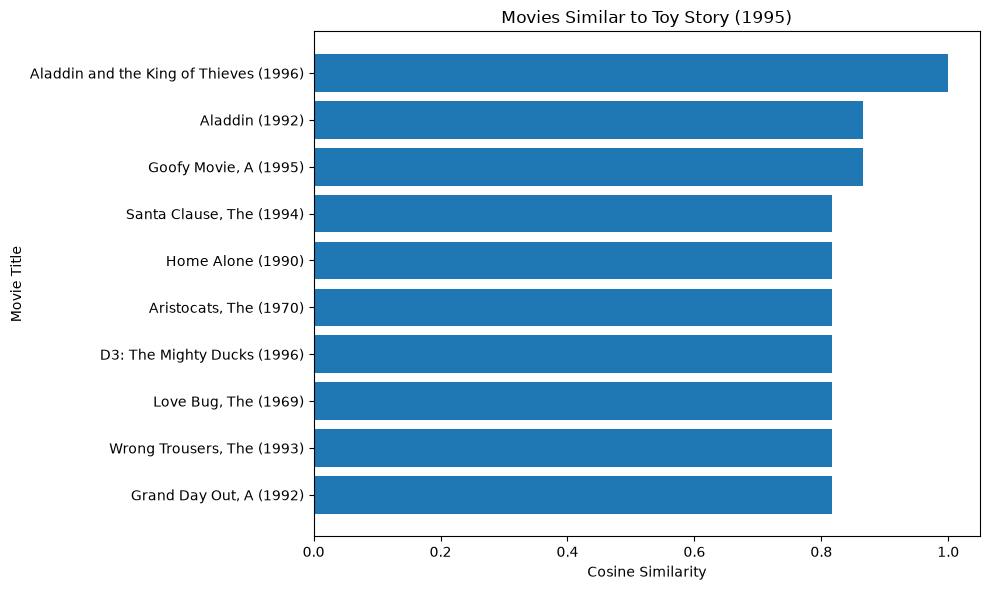

In [39]:
plt.figure(figsize=(10, 6))

plt.barh(
    toy_story_recommendations["title"],
    toy_story_recommendations["similarity"]
)

plt.xlabel("Cosine Similarity")
plt.ylabel("Movie Title")
plt.title("Movies Similar to Toy Story (1995)")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [40]:
# Create the user-item rating matrix

user_item_matrix = ratings.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

# Replace missing values with 0
user_item_matrix = user_item_matrix.fillna(0)

print("User-Item Matrix Created!")
print("Matrix shape:", user_item_matrix.shape)

print("\nFirst 5 users and first 10 movies:")

display(user_item_matrix.iloc[:5, :10])

User-Item Matrix Created!
Matrix shape: (943, 1682)

First 5 users and first 10 movies:


movie_id,1,2,3,4,5,6,7,8,9,10
user_id,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,5.0,4.0,1.0,5.0,3.0
2,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [41]:
# Total possible user-movie combinations

total_possible_ratings = (
    user_item_matrix.shape[0] *
    user_item_matrix.shape[1]
)

# Actual ratings

actual_ratings = (user_item_matrix > 0).sum().sum()

# Missing ratings

missing_ratings = total_possible_ratings - actual_ratings

# Sparsity percentage

sparsity = (
    missing_ratings / total_possible_ratings
) * 100

print("Total possible ratings:", total_possible_ratings)
print("Actual ratings:", actual_ratings)
print("Missing ratings:", missing_ratings)
print("Sparsity:", round(sparsity, 2), "%")

Total possible ratings: 1586126
Actual ratings: 100000
Missing ratings: 1486126
Sparsity: 93.7 %


In [42]:
from sklearn.metrics.pairwise import cosine_similarity

print("Calculating user similarity...")

user_similarity = cosine_similarity(user_item_matrix)

print("User similarity calculation completed!")

print("Similarity matrix shape:", user_similarity.shape)

print("\nSimilarity between first 5 users:")

print(np.round(user_similarity[:5, :5], 3))

Calculating user similarity...
User similarity calculation completed!
Similarity matrix shape: (943, 943)

Similarity between first 5 users:
[[1.    0.167 0.047 0.064 0.378]
 [0.167 1.    0.111 0.178 0.073]
 [0.047 0.111 1.    0.344 0.021]
 [0.064 0.178 0.344 1.    0.032]
 [0.378 0.073 0.021 0.032 1.   ]]


In [43]:
# Select a user
target_user_id = 1

# Find the row position of this user
user_position = user_item_matrix.index.get_loc(target_user_id)

# Get similarity scores for this user
similarity_scores = user_similarity[user_position]

# Create a DataFrame
similar_users = pd.DataFrame({
    "user_id": user_item_matrix.index,
    "similarity": similarity_scores
})

# Remove the target user
similar_users = similar_users[
    similar_users["user_id"] != target_user_id
]

# Sort by similarity
similar_users = similar_users.sort_values(
    by="similarity",
    ascending=False
)

# Select top 10 similar users
top_similar_users = similar_users.head(10)

print("TARGET USER:", target_user_id)
print("\nTOP 10 SIMILAR USERS")
print("----------------------")

display(top_similar_users.reset_index(drop=True))

TARGET USER: 1

TOP 10 SIMILAR USERS
----------------------


,user_id,similarity
0,916,0.569066
1,864,0.547548
2,268,0.542077
3,92,0.540534
4,435,0.538665
5,457,0.538476
6,738,0.527031
7,429,0.525950
8,303,0.525718
9,276,0.524523


In [48]:
def recommend_movies_user_based(
    target_user_id,
    number_of_recommendations=10,
    number_of_similar_users=50,
    minimum_ratings=3
):

    if target_user_id not in user_item_matrix.index:
        print("User not found!")
        return

    # Find target user's similarity scores
    user_position = user_item_matrix.index.get_loc(target_user_id)

    similarity_series = pd.Series(
        user_similarity[user_position],
        index=user_item_matrix.index
    )

    # Remove target user and non-positive similarities
    similarity_series = similarity_series.drop(target_user_id)

    similarity_series = similarity_series[
        similarity_series > 0
    ]

    # Select top similar users
    similar_users = similarity_series.nlargest(
        number_of_similar_users
    )

    # Get their ratings
    neighbor_ratings = user_item_matrix.loc[
        similar_users.index
    ]

    # Identify actual ratings
    rated_mask = neighbor_ratings > 0

    # Calculate weighted rating sum
    weighted_rating_sum = neighbor_ratings.mul(
        similar_users,
        axis=0
    ).sum(axis=0)

    # Calculate supporting similarity weight
    similarity_weight_sum = rated_mask.mul(
        similar_users,
        axis=0
    ).sum(axis=0)

    # Count how many neighbors rated each movie
    rating_counts = rated_mask.sum(axis=0)

    # Calculate predicted ratings
    predicted_ratings = (
        weighted_rating_sum / similarity_weight_sum
    )

    # Exclude already-rated movies
    target_ratings = user_item_matrix.loc[target_user_id]

    predicted_ratings = predicted_ratings[
        target_ratings == 0
    ]

    # Require sufficient supporting ratings
    predicted_ratings = predicted_ratings[
        rating_counts >= minimum_ratings
    ]

    predicted_ratings = predicted_ratings.dropna()

    # Sort by predicted rating
    predicted_ratings = predicted_ratings.sort_values(
        ascending=False
    )

    # Select top recommendations
    top_predictions = predicted_ratings.head(
        number_of_recommendations
    )

    # Create results
    recommendations = pd.DataFrame({
        "movie_id": top_predictions.index,
        "predicted_rating": top_predictions.values,
        "number_of_ratings": rating_counts.loc[
            top_predictions.index
        ].values
    })

    # Add movie titles
    recommendations = recommendations.merge(
        movies[["movie_id", "title"]],
        on="movie_id",
        how="left"
    )

    return recommendations[
        ["movie_id", "title", "predicted_rating", "number_of_ratings"]
    ].reset_index(drop=True)

In [49]:
print("PERSONALIZED MOVIE RECOMMENDATIONS")
print("===================================")

user_recommendations = recommend_movies_user_based(
    target_user_id=1,
    number_of_recommendations=10,
    number_of_similar_users=20
)

display(user_recommendations)

PERSONALIZED MOVIE RECOMMENDATIONS


,movie_id,title,predicted_rating,number_of_ratings
0,313,Titanic (1997),4.838149,6
1,513,"Third Man, The (1949)",4.745961,4
2,653,Touch of Evil (1958),4.663226,3
3,483,Casablanca (1942),4.624916,13
4,1019,"Die xue shuang xiong (Killer, The) (1989)",4.501886,4
5,705,Singin' in the Rain (1952),4.497320,4
6,480,North by Northwest (1959),4.492783,6
7,408,"Close Shave, A (1995)",4.458524,11
8,919,"City of Lost Children, The (1995)",4.451417,9
9,357,One Flew Over the Cuckoo's Nest (1975),4.439681,16


In [50]:
# Select User 1
target_user_id = 1

# Find the 20 most similar users
user_position = user_item_matrix.index.get_loc(target_user_id)

similarity_series = pd.Series(
    user_similarity[user_position],
    index=user_item_matrix.index
).drop(target_user_id)

similar_users = similarity_series[
    similarity_series > 0
].nlargest(20)

# Get their ratings
neighbor_ratings = user_item_matrix.loc[similar_users.index]

# Inspect the recommended movies
recommended_ids = user_recommendations["movie_id"].tolist()

diagnostics = []

for movie_id in recommended_ids:

    movie_ratings = neighbor_ratings[movie_id]

    # Only consider users who actually rated this movie
    actual_ratings = movie_ratings[movie_ratings > 0]

    diagnostics.append({
        "movie_id": movie_id,
        "title": movies.loc[
            movies["movie_id"] == movie_id, "title"
        ].iloc[0],
        "number_of_ratings": len(actual_ratings),
        "average_rating": actual_ratings.mean(),
        "minimum_rating": actual_ratings.min(),
        "maximum_rating": actual_ratings.max()
    })

diagnostics_df = pd.DataFrame(diagnostics)

display(diagnostics_df)

,movie_id,title,number_of_ratings,average_rating,minimum_rating,maximum_rating
0,313,Titanic (1997),6,4.833333,4.0,5.0
1,513,"Third Man, The (1949)",4,4.750000,4.0,5.0
2,653,Touch of Evil (1958),3,4.666667,4.0,5.0
3,483,Casablanca (1942),13,4.615385,4.0,5.0
4,1019,"Die xue shuang xiong (Killer, The) (1989)",4,4.500000,4.0,5.0
5,705,Singin' in the Rain (1952),4,4.500000,4.0,5.0
6,480,North by Northwest (1959),6,4.500000,4.0,5.0
7,408,"Close Shave, A (1995)",11,4.454545,3.0,5.0
8,919,"City of Lost Children, The (1995)",9,4.444444,4.0,5.0
9,357,One Flew Over the Cuckoo's Nest (1975),16,4.437500,3.0,5.0


In [51]:
# Calculate predictions for User 1 using 20 neighbors

print("Prediction statistics:")
print(user_recommendations["predicted_rating"].describe())

print("\nNumber of unique predicted ratings:")
print(user_recommendations["predicted_rating"].nunique())

Prediction statistics:
count    10.000000
mean      4.571386
std       0.139008
min       4.439681
25%       4.467089
50%       4.499603
75%       4.653648
max       4.838149
Name: predicted_rating, dtype: float64

Number of unique predicted ratings:
10


In [52]:
from sklearn.model_selection import train_test_split

# Split ratings into training and testing datasets

train_data, test_data = train_test_split(
    ratings,
    test_size=0.20,
    random_state=42
)

print("Dataset splitting completed!")
print("------------------------------")

print("Original ratings:", len(ratings))
print("Training ratings:", len(train_data))
print("Testing ratings:", len(test_data))

print(
    "Training percentage:",
    round(len(train_data) / len(ratings) * 100, 2),
    "%"
)

print(
    "Testing percentage:",
    round(len(test_data) / len(ratings) * 100, 2),
    "%"
)

Dataset splitting completed!
------------------------------
Original ratings: 100000
Training ratings: 80000
Testing ratings: 20000
Training percentage: 80.0 %
Testing percentage: 20.0 %


In [53]:
# Create training user-item matrix

train_matrix = train_data.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
).reindex(
    index=user_item_matrix.index,
    columns=user_item_matrix.columns
).fillna(0)

print("Training matrix created!")
print("Matrix shape:", train_matrix.shape)

# Calculate user similarity using training data only

print("\nCalculating training user similarities...")

train_user_similarity = cosine_similarity(train_matrix)

print("Training similarity calculation completed!")
print("Similarity matrix shape:", train_user_similarity.shape)

Training matrix created!
Matrix shape: (943, 1682)

Calculating training user similarities...
Training similarity calculation completed!
Similarity matrix shape: (943, 943)


In [54]:
# ==========================================
# USER-BASED COLLABORATIVE FILTERING
# PREDICTION ON TEST DATA
# ==========================================

import numpy as np
import pandas as pd

# Settings
K = 50  # Number of similar users to consider

# Calculate fallback averages using TRAINING data only
train_global_mean = train_data["rating"].mean()

train_user_means = train_data.groupby("user_id")["rating"].mean()

# Precompute the 50 most similar users for every user
print("Finding similar users...")

user_neighbors = {}

for user_id in train_matrix.index:

    user_position = train_matrix.index.get_loc(user_id)

    similarities = pd.Series(
        train_user_similarity[user_position],
        index=train_matrix.index
    )

    # Exclude the target user
    similarities = similarities.drop(user_id)

    # Keep positive similarities and select top K
    neighbors = similarities[similarities > 0].nlargest(K)

    user_neighbors[user_id] = neighbors

print("Similar users calculated for all users!")

# Prediction function
def predict_rating_user_based(user_id, movie_id):

    # Handle unknown users or movies
    if user_id not in train_matrix.index:
        return train_global_mean

    if movie_id not in train_matrix.columns:
        return train_global_mean

    # Get similar users
    neighbors = user_neighbors[user_id]

    # Find their ratings for the target movie
    neighbor_ratings = train_matrix.loc[
        neighbors.index, movie_id
    ]

    # Keep only users who actually rated this movie
    rated_mask = neighbor_ratings > 0

    neighbor_ratings = neighbor_ratings[rated_mask]
    neighbor_similarities = neighbors[rated_mask]

    # If nobody rated the movie, use target user's average
    if len(neighbor_ratings) == 0:
        return train_user_means.get(user_id, train_global_mean)

    # Calculate similarity-weighted prediction
    prediction = np.average(
        neighbor_ratings,
        weights=neighbor_similarities
    )

    # Keep prediction within the 1–5 rating scale
    return float(np.clip(prediction, 1, 5))


# Predict ratings for all test records
print("\nPredicting test ratings...")

predicted_ratings = []

for row in test_data.itertuples(index=False):

    prediction = predict_rating_user_based(
        row.user_id,
        row.movie_id
    )

    predicted_ratings.append(prediction)

print("Prediction completed!")

# Store actual and predicted ratings
evaluation_results = test_data[
    ["user_id", "movie_id", "rating"]
].copy()

evaluation_results["predicted_rating"] = predicted_ratings

print("\nEvaluation dataset:")
display(evaluation_results.head(10))

print("\nTotal predictions:", len(predicted_ratings))
print("Average predicted rating:", round(np.mean(predicted_ratings), 3))
print("Minimum predicted rating:", round(np.min(predicted_ratings), 3))
print("Maximum predicted rating:", round(np.max(predicted_ratings), 3))

Finding similar users...
Similar users calculated for all users!

Predicting test ratings...
Prediction completed!

Evaluation dataset:


,user_id,movie_id,rating,predicted_rating
75721,877,381,4,3.450647
80184,815,602,3,3.993571
19864,94,431,4,3.526760
76699,416,875,2,3.043103
92991,500,182,2,3.934353
76434,259,1074,3,2.492451
84004,598,286,5,3.454291
80917,886,496,4,3.832959
60767,837,15,3,3.537121
50074,521,184,4,3.541902



Total predictions: 20000
Average predicted rating: 3.531
Minimum predicted rating: 1.0
Maximum predicted rating: 5.0


In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual and predicted ratings
actual_ratings = evaluation_results["rating"]
predicted_ratings = evaluation_results["predicted_rating"]

# Calculate MAE
mae = mean_absolute_error(
    actual_ratings,
    predicted_ratings
)

# Calculate RMSE
rmse = np.sqrt(
    mean_squared_error(
        actual_ratings,
        predicted_ratings
    )
)

print("COLLABORATIVE FILTERING EVALUATION")
print("----------------------------------")
print("Total predictions:", len(evaluation_results))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

COLLABORATIVE FILTERING EVALUATION
----------------------------------
Total predictions: 20000
MAE: 0.8149
RMSE: 1.0316


In [56]:
# Calculate the average rating in training data
global_mean = train_data["rating"].mean()

# Predict the same average for every test rating
baseline_predictions = np.full(
    len(test_data),
    global_mean
)

# Calculate baseline errors
baseline_mae = mean_absolute_error(
    test_data["rating"],
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test_data["rating"],
        baseline_predictions
    )
)

print("BASELINE VS COLLABORATIVE FILTERING")
print("-----------------------------------")

print("Baseline MAE:", round(baseline_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))

print("\nCollaborative Filtering MAE:", round(mae, 4))
print("Collaborative Filtering RMSE:", round(rmse, 4))

BASELINE VS COLLABORATIVE FILTERING
-----------------------------------
Baseline MAE: 0.942
Baseline RMSE: 1.1239

Collaborative Filtering MAE: 0.8149
Collaborative Filtering RMSE: 1.0316


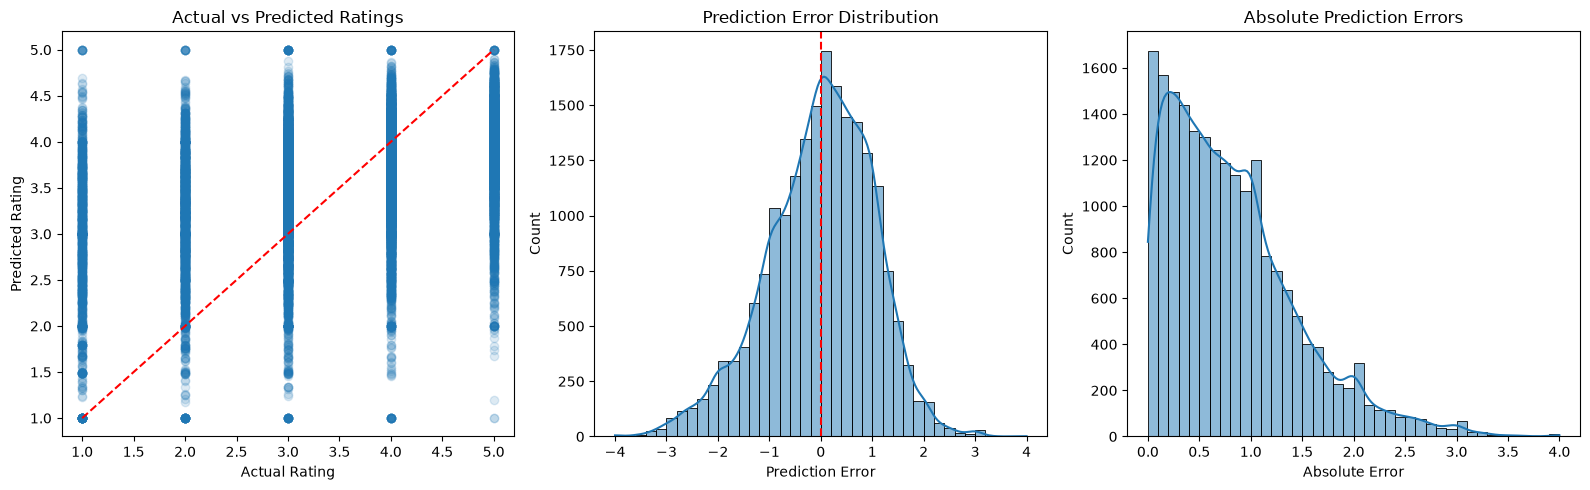

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate prediction errors
evaluation_results["error"] = (
    evaluation_results["rating"]
    - evaluation_results["predicted_rating"]
)

evaluation_results["absolute_error"] = (
    evaluation_results["error"].abs()
)

# Create visualizations
plt.figure(figsize=(16, 5))

# 1. Actual vs Predicted Ratings
plt.subplot(1, 3, 1)

plt.scatter(
    evaluation_results["rating"],
    evaluation_results["predicted_rating"],
    alpha=0.15
)

plt.plot([1, 5], [1, 5], "r--")

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Ratings")

# 2. Prediction Error Distribution
plt.subplot(1, 3, 2)

sns.histplot(
    evaluation_results["error"],
    bins=40,
    kde=True
)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Prediction Error")
plt.title("Prediction Error Distribution")

# 3. Absolute Error Distribution
plt.subplot(1, 3, 3)

sns.histplot(
    evaluation_results["absolute_error"],
    bins=40,
    kde=True
)

plt.xlabel("Absolute Error")
plt.title("Absolute Prediction Errors")

plt.tight_layout()
plt.show()

In [60]:
%pip install streamlit
import streamlit as st

print("Streamlit version:", st.__version__)

  Using cached streamlit-1.67.0-py3-none-any.whl.metadata (10 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pyarrow-26.0.1-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached anyio-4.16.0-py3-none-any.whl.metadata (4.7 kB)
  Using cached python_multipart-0.0.34-py3-none-any.whl.metadata (6.3 kB)
  Using cached websockets-17.4-cp314-cp314-win_amd64.whl.metadata (6.5 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-7.1.0-py3-none-win_amd64.whl.metadata (62 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jsonschema-4.26.0-py3-none-